# Spatial transcriptomics (single-cell resolution)

A template for ST data where every cell has a position in the tissue (MERFISH, Xenium, Stereo-seq,
Slide-seq, ...). The tissue distance comes straight from the coordinates, so no mapping step is
needed. Point the path below at your data and set the cluster names; `quickstart.ipynb` runs the
same steps on synthetic data, with outputs.

The outputs below come from the regenerating axolotl telencephalon (Stereo-seq, 15 days after injury; Wei et al. 2022), the section of the DeltaTrace paper's Figures 4 and 5, run with Figure 4's settings.

In [1]:
import anndata as ad
import numpy as np
import pandas as pd
import scanpy as sc
from scipy.spatial.distance import cdist

import deltatrace as dt

## Load and preprocess

`adata` needs raw counts, a cluster label per cell in `obs`, and the cell coordinates in
`obsm["spatial"]`. `um_per_unit` converts the coordinates to microns (1.0 if they already are).

In [2]:
adata = sc.read_h5ad("path/to/st.h5ad")

cluster_key = "clusters"          # column of adata.obs holding the labels
sources = ["reaEGC", "wntEGC"]    # where the trajectory starts
sinks = ["nptxEX", "mpEX", "dpEX"]   # the terminal fates (see source-only below if unknown)
um_per_unit = 250 / 800           # coordinate units -> microns (800 pixels per 250 um)

adata.obsm["spatial"] = np.asarray(adata.obsm["spatial"], dtype=float) * um_per_unit

sc.pp.filter_genes(adata, min_counts=1)
sc.pp.normalize_total(adata)
sc.pp.log1p(adata)
sc.pp.pca(adata)
sc.pp.neighbors(adata, n_pcs=20)

## Build the graphs

The distance between cell coordinates is the tissue distance, and `pp.integrate` combines it with the
expression graph. It takes the cells' expression as `adata_sc` (here the ST cells themselves) and stores
two graphs: the integrated graph `"intr"` and the expression graph `"expr"`. Measured distances are exact, so keep only short edges (`p_keep=0.08`, the setting of the
DeltaTrace paper's ST data): then no edge jumps across a gap in the tissue, such as the ventricle here. The distance matrix grows with the square of the number of cells, so subset very
large sections (tens of thousands of cells) first.

In [3]:
coords = adata.obsm["spatial"]
adata_dist = ad.AnnData(X=cdist(coords, coords), obs=pd.DataFrame(index=adata.obs_names))

ad_intg = dt.pp.integrate(
    adata_sc=adata,
    adata_dist=adata_dist,
    p_keep=0.08,  # exact distances: keep only short edges
)

building the 'expr' graph ... finished (0.14 s)


building the 'intr' graph ... finished (0.03 s)


done.


## Endpoints

`tl.trajectory` runs `tl.endpoints`, `tl.qrot`, `tl.compute_velocity_grid` and `tl.lineages` in
turn; here they are called one at a time. Sampling the endpoints first lets you check the source
and sink cells before solving. `graph="intr"` picks the integrated graph, and `tl.endpoints` returns
the sampled problem that `pl.endpoints` and `tl.qrot` take as `graph_result`; `tl.lineages` calls the
sinks `terminal_clusters`.

`sampling_mode` and `alloc_power` are the endpoint settings of the DeltaTrace paper's Figure 4 (the
defaults are centered sampling and `alloc_power=1`): source cells are drawn at random within their
clusters, sink cells around each cluster's center, and each role's endpoints (`p_end`, 15% of its
clusters' cells) are shared among its clusters in proportion to the square root of their sizes, so small
clusters get more than a proportional share.

sampling source and sink endpoints ... 

finished (0.31 s)


done.


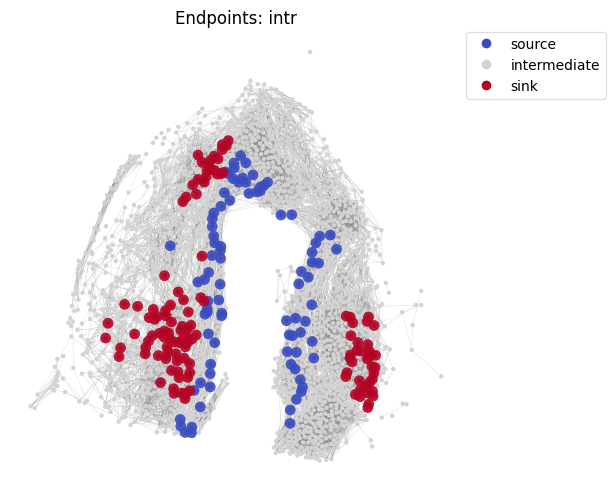

In [4]:
gr = dt.tl.endpoints(
    ad_intg,
    source_clusters=sources,
    sink_clusters=sinks,
    cluster_key=cluster_key,
    graph="intr",
    sampling_mode={"source": "random", "sink": "centered"},
    alloc_power=0.5,
)
dt.pl.endpoints(
    ad_intg,
    gr,
)

## Pseudotime, flow and lineages

solving quadratically regularized transport ... finished (0.16 s)


done.


building the velocity grid ... finished (0.00 s)


done.


assigning lineages by absorbing chain ... finished (0.01 s)


done.


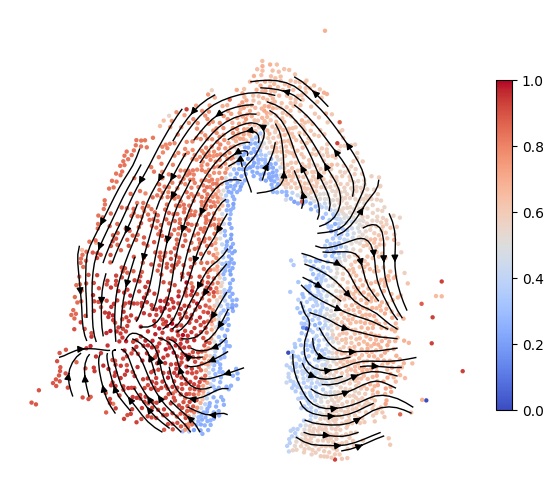

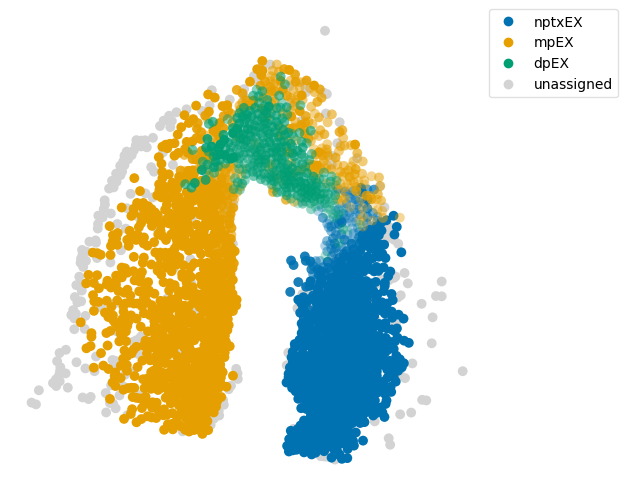

In [5]:
dt.tl.qrot(
    graph_result=gr,
    adata=ad_intg,
    graph="intr",
)
dt.tl.compute_velocity_grid(
    adata=ad_intg,
    basis="spatial",
)
dt.tl.lineages(
    adata=ad_intg,
    source_clusters=sources,
    terminal_clusters=sinks,
    cluster_key=cluster_key,
)

dt.pl.pseudotime(
    adata=ad_intg,
    arrows="stream",
    node_size=10,
)
dt.pl.lineages(adata=ad_intg)

Equivalently, in one call

```python
dt.tl.trajectory(
    adata=ad_intg,
    source_clusters=sources,
    sink_clusters=sinks,
    cluster_key=cluster_key,
    sampling_mode={"source": "random", "sink": "centered"},
    alloc_power=0.5,
)
```

### Plotting with scanpy

Everything the `dt.pl` functions color by is a plain `obs` column (`pseudotime`, `lineage`,
`lineage_confidence`, `fate_<lineage>`, `endpoint_<graph>`), so scanpy draws the same results, and
`dt.pl.velocity` adds the flow arrows to any axes.

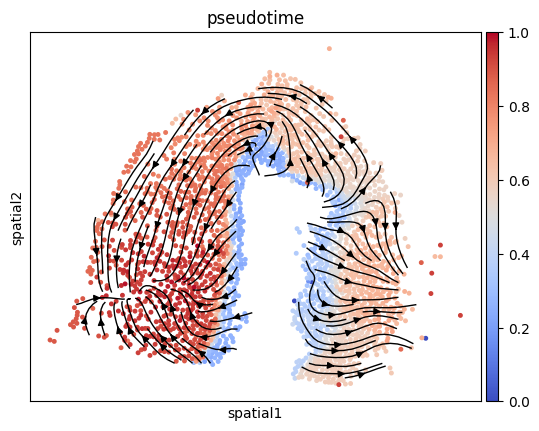

In [6]:
ax = sc.pl.embedding(ad_intg, basis="spatial", color="pseudotime", cmap="coolwarm", show=False)
dt.pl.velocity(
    adata=ad_intg,
    ax=ax,
    basis="spatial",
    kind="stream",
);

## Source-only

Without annotated sinks, `sink_clusters=None` runs source-only; every non-source cell absorbs the
flow and the clusters are ranked by how terminal they are. Pick the fates from the ranking, then
either cut it by their number or run again with them as sinks, which gives the better
trajectory.

sampling source and sink endpoints ... finished (0.00 s)


solving quadratically regularized transport ... finished (0.08 s)


building the velocity grid ... finished (0.01 s)


cluster terminality (term_score = 1 - flow_out/flow_in, higher = more terminal):
         flow_in  flow_out  absorbed  term_score
nptxEX    0.1314    0.0330    0.0984      0.7492
scgnIN    0.0035    0.0012    0.0022      0.6407
mpEX      0.5131    0.2050    0.3081      0.6005
MSN       0.1601    0.0750    0.0851      0.5315
sstIN     0.0883    0.0421    0.0462      0.5228
VLMC      0.2588    0.1358    0.1229      0.4750
npyIN     0.0538    0.0349    0.0189      0.3516
IMN       0.2642    0.1719    0.0923      0.3495
dpEX      0.1300    0.0877    0.0423      0.3252
rIPC2     0.2818    0.2061    0.0756      0.2684
CP        0.0418    0.0312    0.0106      0.2527
rIPC1     0.3532    0.2692    0.0840      0.2378
sfrpEGC   0.0982    0.0848    0.0133      0.1359

suggested terminals: ['nptxEX', 'scgnIN', 'mpEX', 'MSN', 'sstIN', 'VLMC'] (n_lineages=6; no clear gap, largest 0.352 -> 0.475)
done.


/tmp/ipykernel_1044647/1922520141.py:2: UserWarning: Source-only run: no lineages assigned. Rerun with sink_clusters=['nptxEX', 'scgnIN', 'mpEX', 'MSN', 'sstIN', 'VLMC'], or call dt.tl.lineages(adata=adata, source_clusters=['reaEGC', 'wntEGC'], n_lineages=6) on this flow.
  res = dt.tl.trajectory(


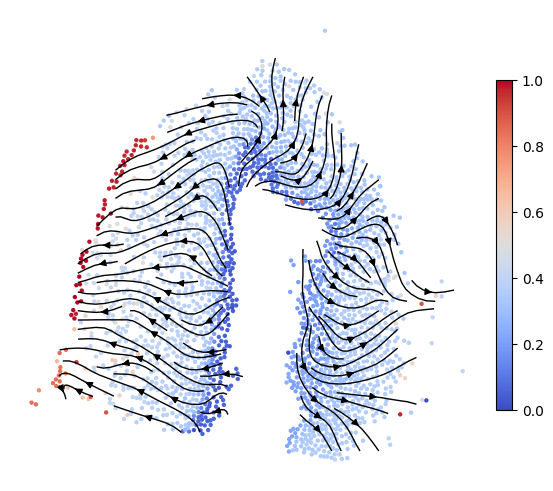

,flow_in,flow_out,absorbed,term_score
nptxEX,0.131401,0.032958,0.098443,0.749177
scgnIN,0.003472,0.001248,0.002225,0.640691
mpEX,0.513074,0.204954,0.308120,0.600537
MSN,0.160091,0.074996,0.085095,0.531540
sstIN,0.088292,0.042129,0.046162,0.522839
VLMC,0.258764,0.135849,0.122914,0.475006
npyIN,0.053776,0.034867,0.018910,0.351639
IMN,0.264187,0.171862,0.092325,0.349468
dpEX,0.129969,0.087700,0.042269,0.325225
rIPC2,0.281776,0.206136,0.075640,0.268439


In [7]:
ad_so = ad_intg.copy()
res = dt.tl.trajectory(
    adata=ad_so,
    source_clusters=sources,
    sink_clusters=None,
    cluster_key=cluster_key,
    sampling_mode={"source": "random", "sink": "centered"},
    alloc_power=0.5,
)
dt.pl.pseudotime(
    adata=ad_so,
    arrows="stream",
    node_size=10,
)
res["terminality"]

Here the ranking has no clear gap, so the number of fates is your call. Three take `scgnIN`,
`nptxEX` and `mpEX`: two of the three sinks used above, and one small cluster.

assigning lineages by absorbing chain ... finished (0.01 s)


done.


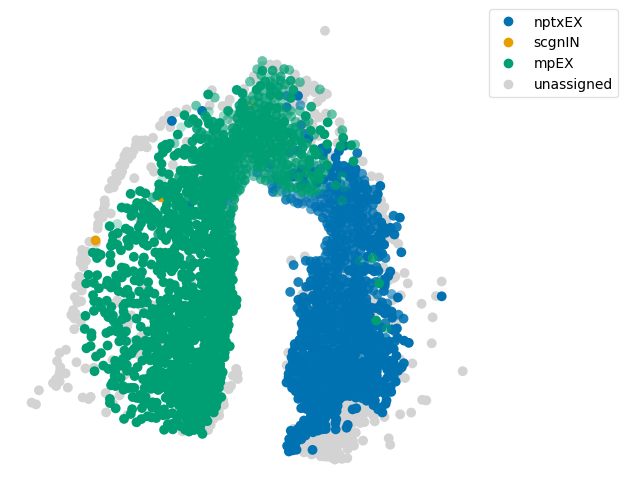

In [8]:
n_fates = 3                       # the number of fates you pick from the ranking
dt.tl.lineages(
    adata=ad_so,
    source_clusters=sources,
    cluster_key=cluster_key,
    n_lineages=n_fates,
)
dt.pl.lineages(adata=ad_so)